# Práctica 3.6 Redes Neuronales
## Universidad Nacional Autónoma de México - Facultad de Ingeniería
## Minería de Datos - Gpo. 03 - Semestre 2027-1
### Autor: Lee Robles Leonardo Alan

---

## **1. Propósito de la práctica**

Diseñar, entrenar y validar una herramienta basada en Redes Neuronales Convolucionales (CNN) para detectar y clasificar software malicioso a través de un mapeo del código binario del malware a una imagen bidimensional utilizando herramientas de *Machine Learning* y el dataset "Malimg".

---

In [1]:
import os 
import random
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix
import torch
from torch import nn
from torch import optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

Image.MAX_IMAGE_PIXELS = None #Avoid Image.DecompressionBombError

# Fixed seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

/home/llee/Codespace/cnn-antivirus/venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## **2. Desarrollo de la práctica**


### 2.1 Análisis exploratorio (EDA) del dataset


#### 2.1.1 Escaneo del dataset y construcción del DataFrame de metadatos

In [2]:
files_registers = []

for root, dirs, files in os.walk('malimg_dataset'):
    for file in files:
        
        attributes = {}

        if not file.endswith('.png'):
            continue

        full_path = os.path.join(root, file)

        attributes['path'] = full_path
        attributes['size_kb'] = os.path.getsize(full_path) / (1024)
        attributes['family'] = os.path.basename(root)

        img = Image.open(full_path)

        attributes['width'] = img.width
        attributes['height'] = img.height
        attributes['resolution'] = (img.width, img.height)
        attributes['mode'] = img.mode

        files_registers.append(attributes)

EDA_df = pd.DataFrame(files_registers)

print(EDA_df)    

                                                    path     size_kb  \
0      malimg_dataset/Adialer.C/000bde2e9a94ba41c0c11...  130.629883   
1      malimg_dataset/Adialer.C/000e30a0819ac7ed931d6...  130.310547   
2      malimg_dataset/Adialer.C/002f06eff1d222560939b...  128.644531   
3      malimg_dataset/Adialer.C/0044f0746b812f6b454ce...  129.931641   
4      malimg_dataset/Adialer.C/0046a83d932a3d431eb21...  129.542969   
...                                                  ...         ...   
24324  malimg_dataset/benign_samples/ffd75eeae728af1c...   72.931641   
24325  malimg_dataset/benign_samples/ffd7d8c2b09ebc6b...   39.780273   
24326  malimg_dataset/benign_samples/ffeac3c6148ba028...  377.186523   
24327  malimg_dataset/benign_samples/fff5b3c1df5296ea...  150.277344   
24328  malimg_dataset/benign_samples/fff8fce615524283...  170.297852   

               family  width  height    resolution mode  
0           Adialer.C    512     410    (512, 410)    L  
1           Adialer

##### 2.1.1.1 Análisis de balance de clases

Utilizamos la función `.value_counts()` de Pandas para obtener el conteo total de imágenes por familia.

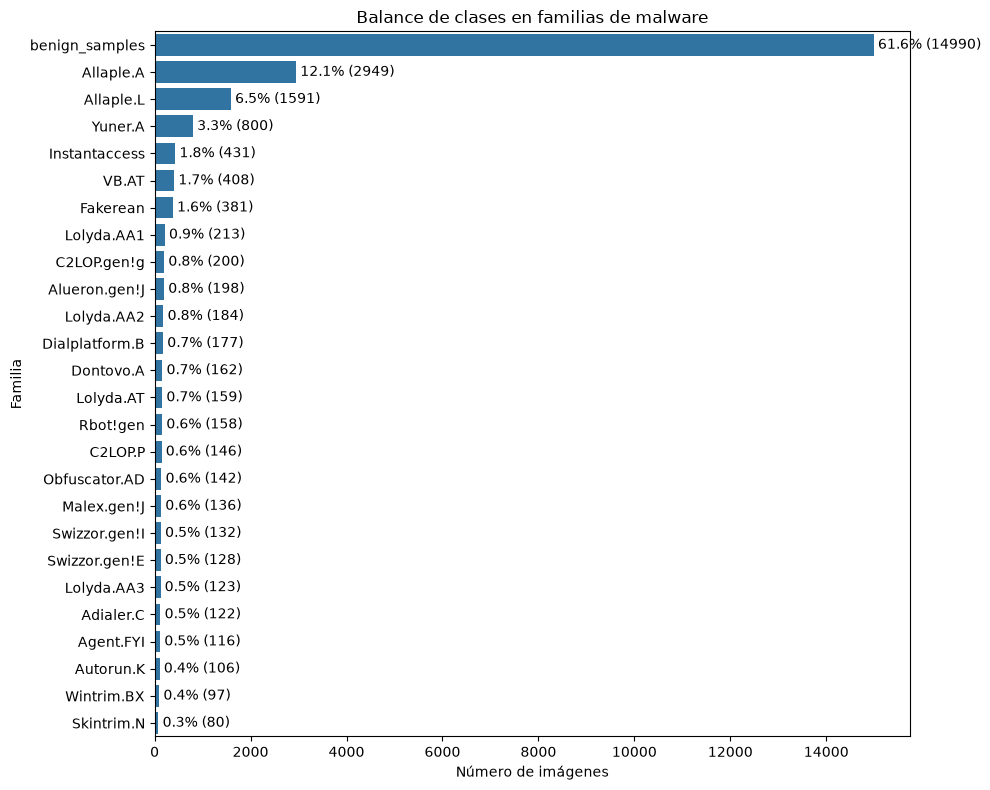

In [3]:
# Count the number of rows per family
counts = EDA_df.value_counts('family')

# Order the families by its size
fam_order = counts.index

# Create plot
plt.figure(figsize=(10,8))
ax = sns.countplot(data=EDA_df, y='family', order=fam_order)

# Calculate percentage
total_images = len(EDA_df)
percentages = [f'{(val / total_images) * 100:.1f}% ({val})' for val in counts]

# Assign labels
ax.bar_label(ax.containers[0], labels=percentages,padding=3)

plt.title('Balance de clases en familias de malware')
plt.xlabel('Número de imágenes')
plt.ylabel('Familia')

plt.tight_layout()
plt.show()

##### 2.1.1.2 Análisis de dimensiones, resoluciones y tamaños

El modelo solamente puede recibir entradas de tamaño fijo, por lo que si las imágenes del *dataset* son muy variadas en cuanto a resolución y tamaño, debemos tener en cuenta la re-escalación de la imagen, introduciendo pérdidas o ruido al modelo.

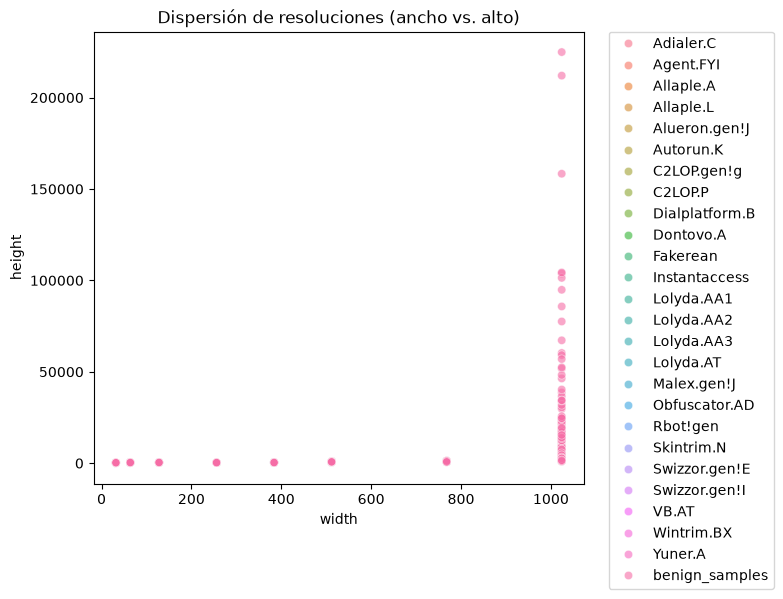

In [4]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=EDA_df, x='width', y='height', hue='family', alpha=0.6)

# To avoid the legend box to cover the plot
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left', borderaxespad=0.)

plt.title('Dispersión de resoluciones (ancho vs. alto)')
plt.tight_layout()
plt.show()

Esto nos indica que diferentes familias de Malware tienen diferentes resoluciones en las imágenes, lo que nos puede dar un indicio para clasificar. 

Ahora, para determinar hacia qué resolución normalizaremos todos las imágenes, observaremos la moda para el ancho y el alto. **Nota:** El ancho toma pocos valores distintos (variable discreta), mientras que el alto toma muchos valores distintos (casi continua).

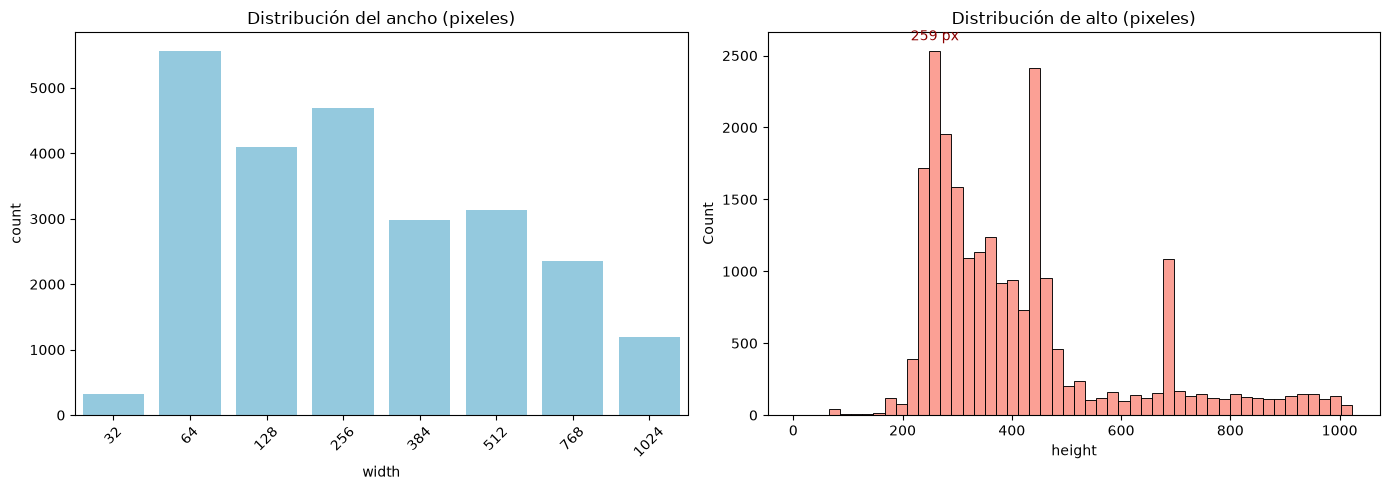

In [5]:
fig, axes = plt.subplots(1,2,figsize=(14,5))

# Width
sns.countplot(data=EDA_df, x='width', ax=axes[0], color='skyblue')
axes[0].set_title('Distribución del ancho (pixeles)')
axes[0].tick_params(axis='x', rotation=45)

# Height
sns.histplot(data=EDA_df[EDA_df['height'] <= 1024], x='height', bins=50, ax=axes[1], color='salmon')
axes[1].set_title('Distribución de alto (pixeles)')

max_patch = max(axes[1].patches, key=lambda p: p.get_height())

# Get the X mid point and the Y height peak
bin_center = max_patch.get_x() + (max_patch.get_width() / 2)
max_height = max_patch.get_height()

axes[1].annotate(
    f'{bin_center:.0f} px', 
    xy=(bin_center, max_height),
    xytext=(0, 5),
    textcoords='offset points',
    ha='center',
    va='bottom', 
    color='darkred'
)

plt.tight_layout()
plt.show()

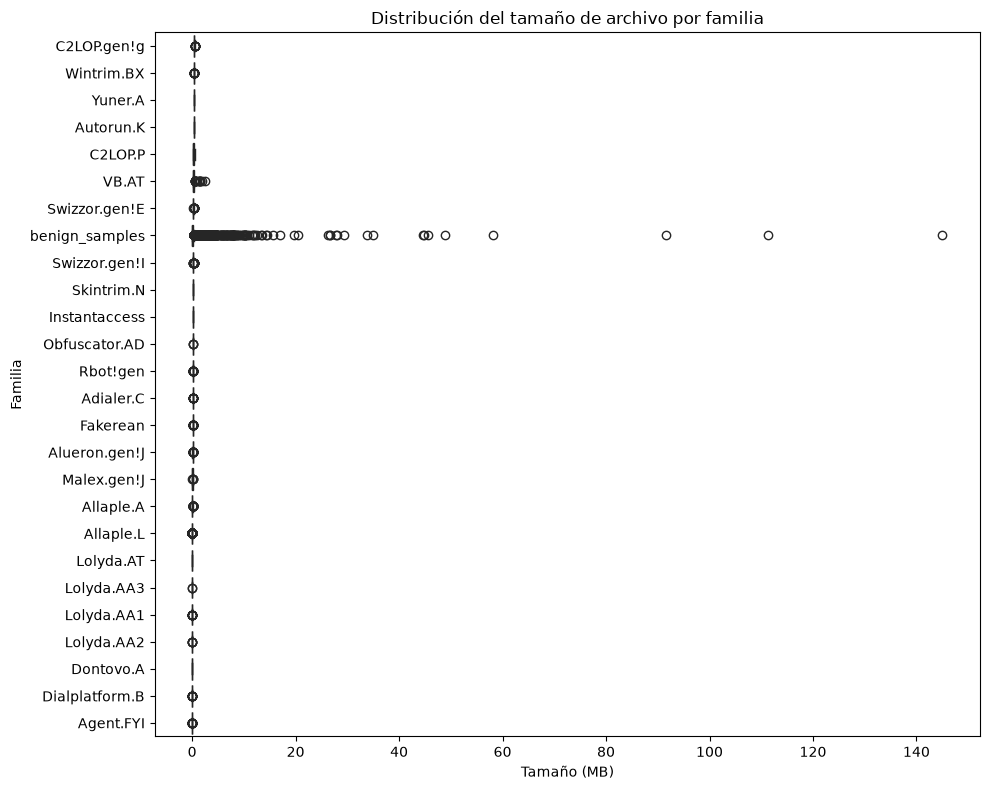

In [6]:
# Convert to MB
EDA_df['size_mb'] = EDA_df['size_kb'] / (1024)

# Calculate the average per family and sort descendingly
avg_sizes = EDA_df.groupby('family')['size_mb'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 8))

order_by_size = avg_sizes.index

sns.boxplot(data=EDA_df, y='family', x='size_mb', order=order_by_size, color='purple')

plt.title('Distribución del tamaño de archivo por familia')
plt.xlabel('Tamaño (MB)')
plt.ylabel('Familia')
plt.tight_layout()
plt.show()

##### 2.1.1.3 Matriz de subplots de imágenes reales

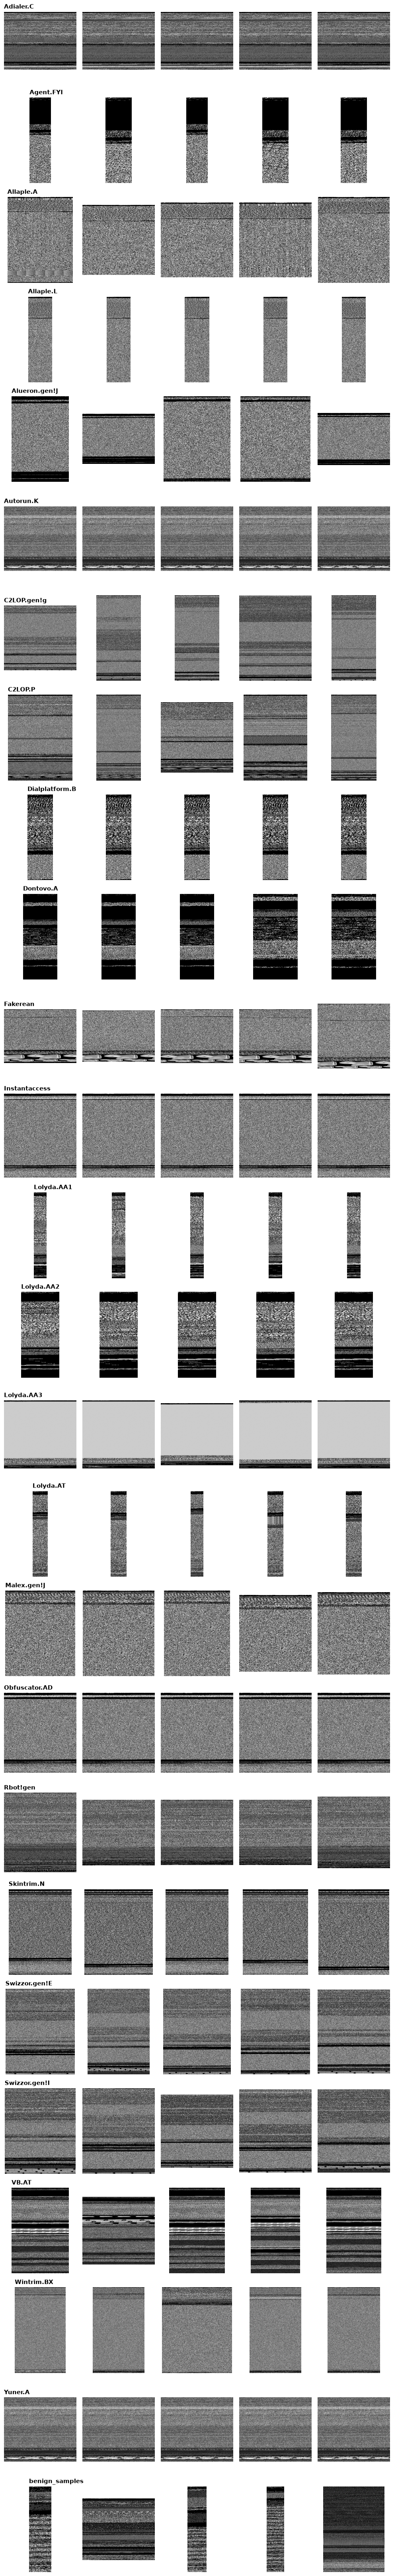

In [7]:
# Define the families to show and the samples per family
families_to_show = EDA_df['family'].unique() #Add [:3] to limit only 3 families.
samples_per_family = 5

# Create the subplots
fig, axes = plt.subplots(
    nrows=len(families_to_show), 
    ncols=samples_per_family, 
    figsize=(10, 2.5 * len(families_to_show))
)

# Iterate per family and render its images
for row_idx, family_name in enumerate(families_to_show):
    # Get the paths of the 'n' images from a family
    family_paths = EDA_df[EDA_df['family'] == family_name]['path'].sample(samples_per_family, random_state=SEED).values
    
    for col_idx in range(samples_per_family):
        ax = axes[row_idx, col_idx] if len(families_to_show) > 1 else axes[col_idx]
        
        # Load and display the images
        img_path = family_paths[col_idx]
        img = Image.open(img_path)
        
        ax.imshow(img, cmap='gray')
        ax.axis('off')
        
        # Family name
        if col_idx == 0:
            ax.set_title(family_name, loc='left', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

##### 2.1.1.4 Distribución de intensidad de píxeles

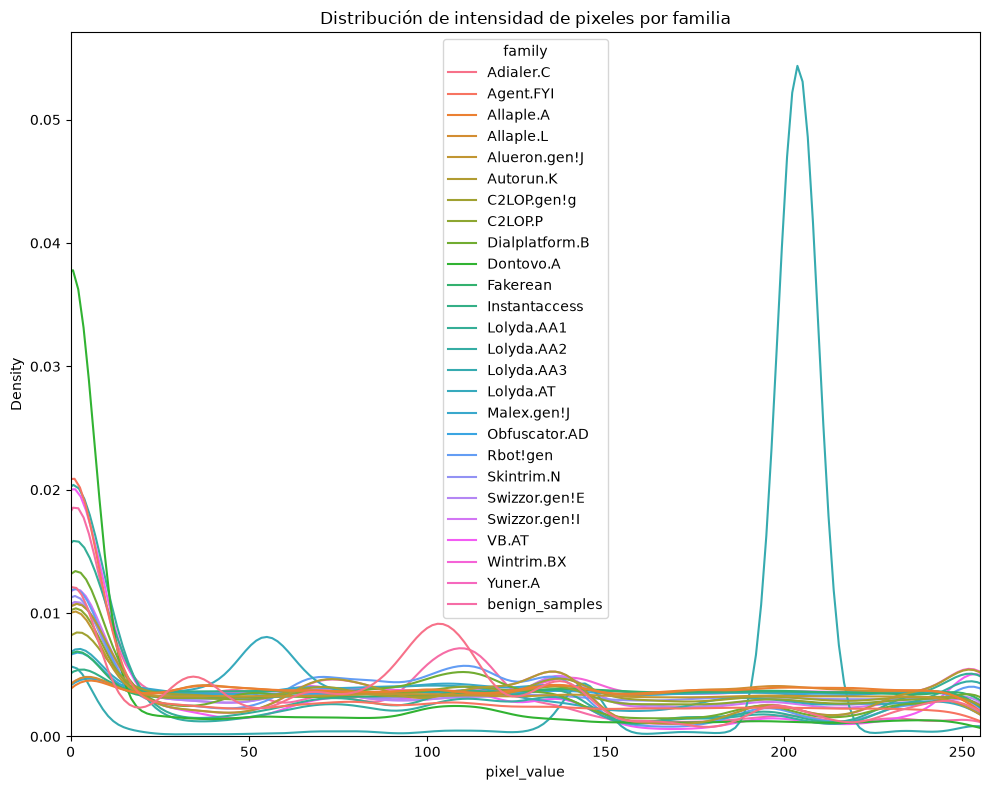

In [8]:
families_to_show = EDA_df['family'].unique() #Add [:3] to limit only 3 families.
samples_per_family = 15

pixel_data = []

for row_idx, family_name in enumerate(families_to_show):

    family_paths = EDA_df[EDA_df['family'] == family_name]['path'].sample(samples_per_family, random_state=SEED).values
    
    for col_idx in range(samples_per_family):

        img_path = family_paths[col_idx]
        img = Image.open(img_path).convert('L')

        img_matrix = np.asarray(img)
        img_vector = img_matrix.flatten()
        img_vector_sample = np.random.choice(img_vector, size = min(len(img_vector), 10000))

        df_temp = pd.DataFrame(
            {
                'pixel_value':img_vector_sample,
                'family': family_name 
            }
        )

        pixel_data.append(df_temp)

px_df = pd.concat(pixel_data, ignore_index=True)

plt.figure(figsize=(10,8))
sns.kdeplot(data=px_df, x='pixel_value', hue='family',common_norm=False)

plt.title('Distribución de intensidad de pixeles por familia')
plt.xlim(0,255)
plt.tight_layout()
plt.show()


        

### 2.2 Preparación de los datos

#### 2.2.1 Separación de los datos

Se dividen los datos en 80% para entrenamiento, 10% para pruebas y 10% para validación

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(
    EDA_df['path'], 
    EDA_df['family'], 
    test_size=0.20, 
    stratify=EDA_df['family'], 
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, 
    y_temp, 
    test_size=0.50, 
    stratify=y_temp, 
    random_state=42
)

print(f"Train samples: {len(X_train)} | Val samples: {len(X_val)} | Test samples: {len(X_test)}")

Train samples: 19463 | Val samples: 2433 | Test samples: 2433


##### 2.2.1.1 Estrategia de balanceo

In [10]:
def calc_weight(y_train):
    classes = np.unique(y_train)

    class_weights_vector = compute_class_weight(
        class_weight='balanced', 
        classes=classes, 
        y=y_train
    )

    class_weights_dict = dict(zip(classes, class_weights_vector))

    class_to_idx = {cls: idx for idx, cls in enumerate(classes)}
    idx_class_weights = {class_to_idx[cls]: weight for cls, weight in class_weights_dict.items()}

    print("Diccionario de pesos por clase:", idx_class_weights)
    
    return idx_class_weights

In [11]:
weights_dict = calc_weight(y_train)

Diccionario de pesos por clase: {0: np.float64(7.6385400313971745), 1: np.float64(8.049214226633582), 2: np.float64(0.31732807252095085), 3: np.float64(0.5880415735089733), 4: np.float64(4.737828627069133), 5: np.float64(8.806787330316743), 6: np.float64(6.3980933596318215), 7: np.float64(4.678605769230769), 8: np.float64(5.309056192034915), 9: np.float64(5.758284023668639), 10: np.float64(2.4543505674653217), 11: np.float64(2.169788182831661), 12: np.float64(4.403393665158371), 13: np.float64(5.09236002093145), 14: np.float64(7.6385400313971745), 15: np.float64(5.894306480920654), 16: np.float64(6.867678193366267), 17: np.float64(6.566464237516869), 18: np.float64(5.941086691086691), 19: np.float64(11.696514423076923), 20: np.float64(7.338989441930618), 21: np.float64(7.062046444121916), 22: np.float64(2.29624823029731), 23: np.float64(9.597140039447732), 24: np.float64(1.1696514423076922), 25: np.float64(0.0624230256068148)}


#### 2.2.2 Transformación de los datos

Los datos pasan por un proceso de *augmentation* (crear nuevos datos a partir de los ya existentes), redimensionamiento (para que las entradas al CNN sean todas del mismo tamaño) y normalización

#### 2.2.2.1 Data augmentation

Provoca variaciones en las imágenes para aumentar la cardinalidad del dataset

In [12]:
def data_augmentation(img_matrix, target_size=(256, 256)):

    # Horizontal flip with a 50% chance
    if np.random.rand() > 0.5:
        img_matrix = np.ascontiguousarray(np.fliplr(img_matrix))

    # Brightness adjustment (between 85% and 115%)
    if np.random.rand() > 0.5:
        factor = np.random.uniform(0.85, 1.15)
        img_matrix = np.clip(img_matrix.astype(np.float32) * factor, 0, 255).astype(np.uint8)

    # Slight crop (crops and resizes)
    if np.random.rand() > 0.5:
        h, w = img_matrix.shape[:2]
        crop_h, crop_w = int(h * 0.90), int(w * 0.90)
        
        top = (h - crop_h) // 2
        left = (w - crop_w) // 2
        
        cropped = img_matrix[top:top + crop_h, left:left + crop_w]
        
        # Resize to 256x256 resolution
        img_pil = Image.fromarray(cropped)
        img_resized = img_pil.resize(target_size, resample=Image.BILINEAR)
        img_matrix = np.asarray(img_resized)

    return img_matrix


##### 2.2.2.2 Estandarización y redimensionamiento

Se decidió tomar la resolución objetivo de 256x256 para todo el dataset, aplicando un redimensionamiento, en lugar de un *zero-padding*. El redimensionamiento se realiza una sola vez por imagen y el resultado se almacena en disco como un arreglo `uint8` (`.npy`) por cada partición, dentro de la carpeta `cache_256`. Durante el entrenamiento, el `Dataset` lee las imágenes ya redimensionadas usando *memory mapping*, por lo que no se cargan completas en RAM ni se vuelven a abrir y redimensionar en cada época. Si se cambia la resolución objetivo o la partición de los datos, hay que borrar esa carpeta para regenerarla. Se utiliza interpolación bilineal en lugar de *nearest neighbor*, ya que al reducir imágenes grandes promedia los píxeles vecinos y evita el *aliasing* (pérdida abrupta de patrones de textura).

In [13]:
def resize_image(img, target_size=(256, 256)):
    return img.resize(target_size, resample=Image.BILINEAR)

In [14]:
CACHE_DIR = 'cache_256'
os.makedirs(CACHE_DIR, exist_ok=True)

def resize_and_cache(paths, name, target_size=(256, 256)):
    """
    Resizes every image once and stores them in disk as a uint8 array of shape (N, H, W).
    If the cache already exists, it is only loaded (memory-mapped).
    """
    cache_path = os.path.join(CACHE_DIR, f'{name}.npy')
    shape = (len(paths), target_size[1], target_size[0])

    # Rebuild the cache if it does not exist or it does not match the current split
    rebuild = True
    if os.path.exists(cache_path):
        rebuild = np.load(cache_path, mmap_mode='r').shape != shape

    if rebuild:
        partial_path = cache_path + '.partial'
        arr = np.lib.format.open_memmap(partial_path, mode='w+', dtype=np.uint8, shape=shape)
        for i, path in enumerate(tqdm(paths, desc=f'Resizing {name}')):
            with Image.open(path) as img:
                arr[i] = np.asarray(resize_image(img.convert('L'), target_size))
        arr.flush()
        del arr
        os.replace(partial_path, cache_path)  # Only a complete cache gets its final name

    return np.load(cache_path, mmap_mode='r')

imgs_train = resize_and_cache(X_train.values, 'train')
imgs_val = resize_and_cache(X_val.values, 'val')
imgs_test = resize_and_cache(X_test.values, 'test')

print(imgs_train.shape, imgs_val.shape, imgs_test.shape)

(19463, 256, 256) (2433, 256, 256) (2433, 256, 256)



##### 2.2.2.3 Normalización

En general, el dataset no presenta sesgos extremos en las intensidades de su píxeles, por lo que se aplicará una normalización min-max.

In [15]:
def normalize_matrix(img_matrix):
    normalized = img_matrix.astype(np.float32) / 255.0
    return np.expand_dims(normalized, axis=-1)

#### 2.2.3 Pipeline de carga


In [16]:
def load_pipeline(img_matrix, is_training=True, target_size=(256, 256)):
    """
    Receives an image already resized to target_size (uint8 matrix, H x W).
    """
    
    if is_training:
        img_matrix = data_augmentation(img_matrix, target_size)
        
    final_tensor = normalize_matrix(img_matrix)
    
    return final_tensor

#### 2.2.4 Dataset y DataLoaders

`load_pipeline` recibe la imagen ya redimensionada (leída desde la caché en disco) y regresa tensores con forma `(H, W, 1)`, pero PyTorch espera `(C, H, W)`, por lo que se reordenan los ejes dentro de un `Dataset`. Las etiquetas se codifican con el mismo orden alfabético de `np.unique` que usa `calc_weight`, para que cada peso corresponda a su clase.

In [17]:
classes = np.unique(y_train)  # same order used in calc_weight
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}

class MalimgDataset(Dataset):
    def __init__(self, images, labels, is_training=False):
        self.images = images  # uint8 array (N, H, W), memory-mapped from disk
        self.labels = labels.map(class_to_idx).values
        self.is_training = is_training

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = load_pipeline(np.array(self.images[idx]), is_training=self.is_training)  # (H, W, 1)
        img = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1)))  # (1, H, W)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, label

BATCH_SIZE = 32

# Augmentation only on the training set
dataloader_train = DataLoader(MalimgDataset(imgs_train, y_train, is_training=True), batch_size=BATCH_SIZE, shuffle=True)
dataloader_val = DataLoader(MalimgDataset(imgs_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
dataloader_test = DataLoader(MalimgDataset(imgs_test, y_test), batch_size=BATCH_SIZE, shuffle=False)



### 2.3 Entrenamiento del modelo


Definir la clase para la red convolucional:

In [18]:
class CNN(nn.Module):
   def __init__(self, in_channels, num_classes):

       """
       Building blocks of convolutional neural network.

       Parameters:
           * in_channels: Number of channels in the input image (for grayscale images, 1)
           * num_classes: Number of classes to predict. In our problem, 26 (25 Malimg malware families + 1 benign class).
       """
       super(CNN, self).__init__()

       # 1st convolutional layer
       self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=8, kernel_size=3, padding=1)
       # Max pooling layer
       self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
       # 2nd convolutional layer
       self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1)
       # 3rd convolutional layer
       self.conv3 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
       # Adaptive pooling: fixes the output at 4x4 regardless of the input resolution
       self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
       # Fully connected layer
       self.fc1 = nn.Linear(32 * 4 * 4, num_classes)

   def forward(self, x):
       """
       Define the forward pass of the neural network.

       Parameters:
           x: Input tensor.

       Returns:
           torch.Tensor
               The output tensor after passing through the network.
       """
       x = F.relu(self.conv1(x))  # Apply first convolution and ReLU activation
       x = self.pool(x)           # Apply max pooling
       x = F.relu(self.conv2(x))  # Apply second convolution and ReLU activation
       x = self.pool(x)           # Apply max pooling
       x = F.relu(self.conv3(x))  # Apply third convolution and ReLU activation
       x = self.adaptive_pool(x)  # Apply adaptive average pooling (4x4)
       x = torch.flatten(x, start_dim=1)  # Flatten the tensor
       x = self.fc1(x)            # Apply fully connected layer
       return x

Entrenar el modelo:

In [19]:
device = "cuda" if torch.cuda.is_available() else "cpu"

NUM_CLASSES = len(weights_dict)  # 25 Malimg families + 1 benign class = 26
model = CNN(in_channels=1, num_classes=NUM_CLASSES).to(device)

weights_tensor = torch.tensor(list(weights_dict.values()), dtype=torch.float).to(device)

In [20]:
# Define the loss function
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

# Define the optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [21]:
num_epochs=10
train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

   model.train()
   running_loss = 0.0
   correct = 0
   total = 0
 # Iterate over training batches
   print(f"Epoch [{epoch + 1}/{num_epochs}]")

   for batch_index, (data, targets) in enumerate(tqdm(dataloader_train)):
       data = data.to(device)
       targets = targets.to(device)
       scores = model(data)
       loss = criterion(scores, targets)
       optimizer.zero_grad()
       loss.backward()
       optimizer.step()

       running_loss += loss.item()
       correct += (scores.argmax(dim=1) == targets).sum().item()
       total += targets.size(0)

   epoch_loss = running_loss / len(dataloader_train)
   epoch_acc = correct / total
   train_losses.append(epoch_loss)
   train_accuracies.append(epoch_acc)
   print(f"  Loss promedio: {epoch_loss:.4f} | Accuracy: {epoch_acc:.4f}")

Epoch [1/10]


100%|██████████| 609/609 [03:33<00:00,  2.86it/s]


  Loss promedio: 1.6599 | Accuracy: 0.5328
Epoch [2/10]


100%|██████████| 609/609 [03:36<00:00,  2.82it/s]


  Loss promedio: 0.7943 | Accuracy: 0.7072
Epoch [3/10]


100%|██████████| 609/609 [03:33<00:00,  2.85it/s]


... (11 outputs left out)

100%|██████████| 609/609 [03:33<00:00,  2.86it/s]


  Loss promedio: 0.2792 | Accuracy: 0.8857
Epoch [10/10]


100%|██████████| 609/609 [03:32<00:00,  2.86it/s]

  Loss promedio: 0.2857 | Accuracy: 0.8602


Curvas de entrenamiento (el *accuracy* se calcula sobre los *batches* de entrenamiento, con *augmentation* activo):

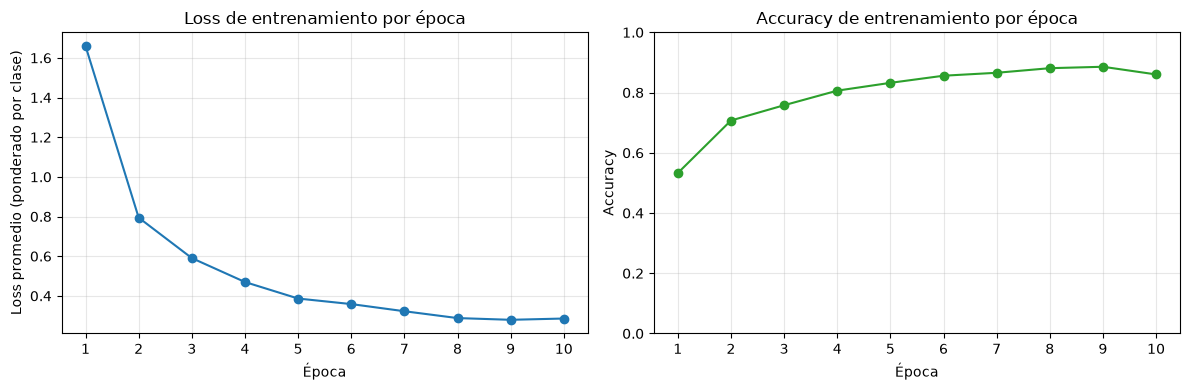

In [22]:
epochs_range = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, train_losses, marker='o')
axes[0].set_title('Loss de entrenamiento por época')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss promedio (ponderado por clase)')
axes[0].set_xticks(list(epochs_range))
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, train_accuracies, marker='o', color='tab:green')
axes[1].set_title('Accuracy de entrenamiento por época')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
axes[1].set_xticks(list(epochs_range))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 2.4 Validación del modelo

Se evalúa el modelo entrenado sobre el conjunto de validación, es decir, imágenes que no vio durante el entrenamiento y a las que no se les aplica *augmentation*. Como las clases están desbalanceadas, además del *accuracy* se reportan el *balanced accuracy* (promedio del *recall* de cada clase) y el F1 macro, que dan el mismo peso a todas las familias.

Para poder diagnosticar *overfitting*, también se evalúa el conjunto de entrenamiento sin *augmentation* (el *accuracy* de las curvas anteriores se midió con *augmentation* activo, por lo que no es comparable directamente).

In [23]:
def evaluate(model, dataloader, criterion, device):
    """
    Evaluates the model without updating its weights.

    Returns the average loss per batch, the true labels and the predicted labels.
    """
    model.eval()
    running_loss = 0.0
    all_preds, all_targets = [], []

    with torch.no_grad():
        for data, targets in tqdm(dataloader):
            data = data.to(device)
            targets = targets.to(device)
            scores = model(data)
            running_loss += criterion(scores, targets).item()
            all_preds.append(scores.argmax(dim=1).cpu())
            all_targets.append(targets.cpu())

    avg_loss = running_loss / len(dataloader)
    return avg_loss, torch.cat(all_targets).numpy(), torch.cat(all_preds).numpy()

# Validation set
val_loss, val_targets, val_preds = evaluate(model, dataloader_val, criterion, device)

# Training set without augmentation (takes about a minute on CPU)
dataloader_train_eval = DataLoader(MalimgDataset(imgs_train, y_train, is_training=False), batch_size=BATCH_SIZE, shuffle=False)
train_loss, train_targets, train_preds = evaluate(model, dataloader_train_eval, criterion, device)

100%|██████████| 609/609 [01:20<00:00,  7.53it/s]


In [24]:
def summarize(name, loss, targets, preds):
    return {
        'conjunto': name,
        'loss': loss,
        'accuracy': accuracy_score(targets, preds),
        'balanced_accuracy': balanced_accuracy_score(targets, preds),
        'f1_macro': f1_score(targets, preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(targets, preds, average='weighted', zero_division=0),
    }

summary_df = pd.DataFrame([
    summarize('Entrenamiento (sin augmentation)', train_loss, train_targets, train_preds),
    summarize('Validación', val_loss, val_targets, val_preds),
])

print(summary_df.round(4).to_string(index=False))

                        conjunto   loss  accuracy  balanced_accuracy  f1_macro  f1_weighted
Entrenamiento (sin augmentation) 0.2368    0.9242             0.9012    0.8024       0.9304
                      Validación 0.2334    0.9346             0.9045    0.8171       0.9382


Una brecha grande entre entrenamiento y validación indica *overfitting*; si ambos valores son bajos, el modelo está subajustado.

A continuación se muestra el desempeño por familia sobre el conjunto de validación:

In [25]:
class_labels = list(range(len(classes)))
class_names = [str(c) for c in classes]

report_df = pd.DataFrame(
    classification_report(val_targets, val_preds, labels=class_labels, target_names=class_names, output_dict=True, zero_division=0)
).T

print(report_df.round(3).to_string())

                precision  recall  f1-score   support
Adialer.C           0.750   1.000     0.857    12.000
Agent.FYI           0.857   1.000     0.923    12.000
Allaple.A           1.000   0.983     0.991   295.000
Allaple.L           0.994   1.000     0.997   159.000
Alueron.gen!J       0.800   1.000     0.889    20.000
Autorun.K           0.000   0.000     0.000    10.000
C2LOP.P             0.789   1.000     0.882    15.000
C2LOP.gen!g         0.889   0.800     0.842    20.000
Dialplatform.B      0.900   1.000     0.947    18.000
Dontovo.A           0.762   1.000     0.865    16.000
Fakerean            0.974   1.000     0.987    38.000
Instantaccess       1.000   0.977     0.988    43.000
Lolyda.AA1          0.618   0.955     0.750    22.000
Lolyda.AA2          1.000   0.778     0.875    18.000
Lolyda.AA3          1.000   1.000     1.000    12.000
Lolyda.AT           0.762   1.000     0.865    16.000
Malex.gen!J         0.722   1.000     0.839    13.000
Obfuscator.AD       0.778   

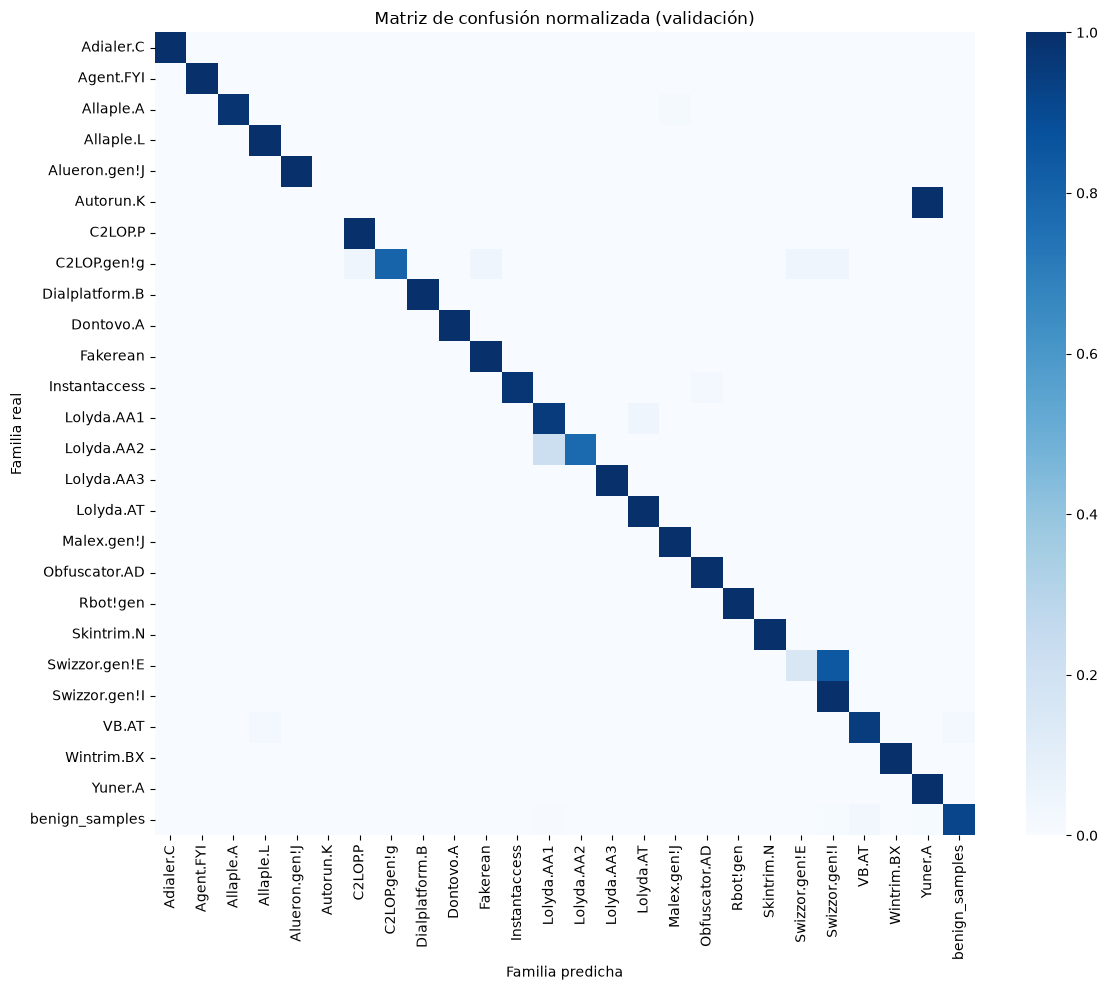

In [26]:
cm = confusion_matrix(val_targets, val_preds, labels=class_labels)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)  # each row sums to 1 (recall per class)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_norm, xticklabels=class_names, yticklabels=class_names, cmap='Blues', vmin=0, vmax=1)

plt.title('Matriz de confusión normalizada (validación)')
plt.xlabel('Familia predicha')
plt.ylabel('Familia real')

plt.tight_layout()
plt.show()

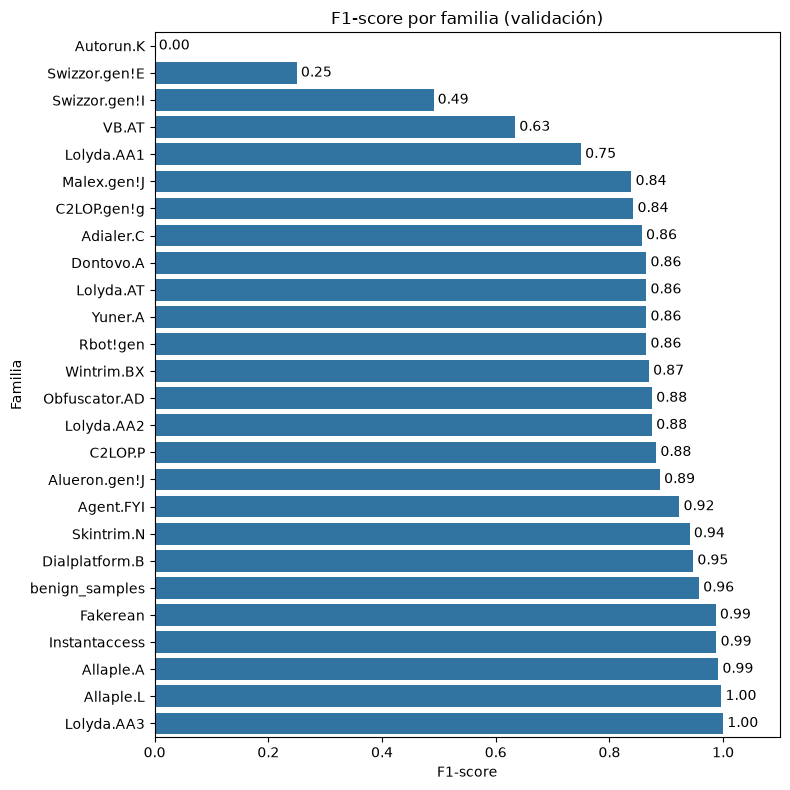

In [27]:
# F1-score per family, sorted from the worst to the best
f1_per_class = report_df.loc[class_names, 'f1-score'].sort_values()

plt.figure(figsize=(8, 8))
ax = sns.barplot(x=f1_per_class.values, y=f1_per_class.index, color='tab:blue')
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)

plt.title('F1-score por familia (validación)')
plt.xlabel('F1-score')
plt.ylabel('Familia')
plt.xlim(0, 1.1)

plt.tight_layout()
plt.show()

Las confusiones más frecuentes entre familias (la diagonal se excluye):

In [28]:
errors = cm.copy()
np.fill_diagonal(errors, 0)

confusions = pd.DataFrame(
    [(class_names[i], class_names[j], errors[i, j]) for i in class_labels for j in class_labels if errors[i, j] > 0],
    columns=['Familia real', 'Familia predicha', 'Imágenes']
).sort_values('Imágenes', ascending=False).head(10)

print(confusions.to_string(index=False))

  Familia real Familia predicha  Imágenes
benign_samples            VB.AT        43
benign_samples    Swizzor.gen!I        15
benign_samples          Yuner.A        15
 Swizzor.gen!E    Swizzor.gen!I        11
     Autorun.K          Yuner.A        10
benign_samples       Lolyda.AA1         9
benign_samples    Alueron.gen!J         5
benign_samples         Rbot!gen         5
     Allaple.A      Malex.gen!J         5
benign_samples        Dontovo.A         5


### 2.5 Pruebas y *testing* del modelo

---

## **3. Resultados**

---

## **4. Conclusiones de la práctica**

### Referencias

- Nataraj, L., Yegneswaran, V., Porras, P., & Zhang, X. (2011). Malware images: Visualization and automatic classification. En Proceedings of the 8th International Symposium on Visualization for Cyber Security (VizSec '11) (pp. 1–7). Association for Computing Machinery. https://dl.acm.org/doi/10.1145/2016904.2016908
